In [48]:
import sys

print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

Python Version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Python Executable: C:\Users\aleez\anaconda3\python.exe


In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

Pandas: 3.0.3
NumPy: 2.4.6
Matplotlib: 3.11.0
Seaborn: 0.13.2


In [50]:
import pandas as pd
import numpy as np

file_path = r"C:\Users\aleez\OneDrive\Documents\Projects\Telco-Customer-Churn\01_DataSet\Telco-Customer-Churn_Raw.txt"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 7043
Columns: 21


In [51]:
# Display first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [52]:
# Display all column names
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [54]:
# Check empty or whitespace-only values
blank_total_charges = df['TotalCharges'].astype(str).str.strip().eq('').sum()

print("Blank TotalCharges values:", blank_total_charges)

Blank TotalCharges values: 11


In [55]:
# Display records with missing TotalCharges
missing_records = df[
    df['TotalCharges'].astype(str).str.strip().eq('')
]

missing_records[['customerID', 'tenure', 'MonthlyCharges',
                 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [56]:
# Create a cleaned numeric version
df['TotalCharges_Clean'] = pd.to_numeric(
    df['TotalCharges'].str.strip(),
    errors='coerce'
)

# Replace missing values with 0 in the new column
df['TotalCharges_Clean'] = df['TotalCharges_Clean'].fillna(0)

print("Original column data type:", df['TotalCharges'].dtype)
print("Cleaned column data type:", df['TotalCharges_Clean'].dtype)
print("Missing values in cleaned column:", df['TotalCharges_Clean'].isna().sum())
print("Zero values in cleaned column:", (df['TotalCharges_Clean'] == 0).sum())

Original column data type: str
Cleaned column data type: float64
Missing values in cleaned column: 0
Zero values in cleaned column: 11


In [57]:
# Check numerical columns
df[['tenure', 'MonthlyCharges', 'TotalCharges_Clean']].describe()

,tenure,MonthlyCharges,TotalCharges_Clean
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [58]:
# Check duplicate customer IDs
duplicate_ids = df['customerID'].duplicated().sum()

print("Duplicate customer IDs:", duplicate_ids)

Duplicate customer IDs: 0



## 1. Initial Dataset Exploration

### Dataset Overview
- Total customers: 7,043
- Original columns: 21
- Duplicate customer IDs: 0
- Missing TotalCharges values: 11

### Numerical Analysis — Key Observations

**Customer Tenure**
- Average tenure is 32.37 months.
- Median tenure is 29 months.
- 25% of customers have tenure of 9 months or less.

**Monthly Charges**
- Average monthly charges are $64.76.
- Median monthly charges are $70.35.
- The mean is lower than the median, suggesting a distribution influenced by lower monthly charges.

**Total Charges**
- Average accumulated charges are $2,279.73.
- Median accumulated charges are $1,394.55.
- Total charges vary considerably across customers, partly reflecting differences in tenure.

### Data Quality Findings
- All 7,043 customer IDs are unique.
- Eleven TotalCharges values were missing.
- All 11 affected customers have zero tenure.
- A separate numeric column, TotalCharges_Clean, was created.
- Missing values were represented as zero in the cleaned column, while the original column was preserved.

**Note:** Zero in TotalCharges_Clean represents missing original data, not confirmed actual charges.


In [59]:
# Select categorical columns
categorical_columns = df.select_dtypes(include=['object', 'str']).columns.tolist()

print("Total categorical columns:", len(categorical_columns))
print("\nCategorical columns:")
print(categorical_columns)

Total categorical columns: 18

Categorical columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [60]:
categorical_features = [
    col for col in categorical_columns
    if col not in ['customerID', 'TotalCharges']
]

print("Total categorical features:", len(categorical_features))
print("\nCategorical features:")
print(categorical_features)

Total categorical features: 16

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [61]:
# Count customers by contract type
contract_counts = df['Contract'].value_counts()

print("Customer Distribution by Contract:")
print(contract_counts)

print("\nPercentage Distribution:")
print((df['Contract'].value_counts(normalize=True) * 100).round(2))

Customer Distribution by Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

Percentage Distribution:
Contract
Month-to-month    55.02
Two year          24.07
One year          20.91
Name: proportion, dtype: float64



### Contract Distribution — Key Findings

- Month-to-month contracts account for 3,875 customers (55.02%).
- Two-year contracts account for 1,695 customers (24.07%).
- One-year contracts account for 1,473 customers (20.91%).
- More than half of the customer base uses month-to-month contracts.

**Business Insight:** The large month-to-month customer segment represents an important retention opportunity. Previous SQL analysis showed that this segment has a 42.71% churn rate.

**Conclusion:** Contract type is an important dimension for further churn and retention analysis.


In [62]:
# Count customers by payment method
payment_counts = df['PaymentMethod'].value_counts()

print("Customer Distribution by Payment Method:")
print(payment_counts)

print("\nPercentage Distribution:")
print((df['PaymentMethod'].value_counts(normalize=True) * 100).round(2))

Customer Distribution by Payment Method:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

Percentage Distribution:
PaymentMethod
Electronic check             33.58
Mailed check                 22.89
Bank transfer (automatic)    21.92
Credit card (automatic)      21.61
Name: proportion, dtype: float64



### Payment Method Distribution — Key Findings

- Electronic check: 2,365 customers (33.58%).
- Mailed check: 1,612 customers (22.89%).
- Automatic bank transfer: 1,544 customers (21.92%).
- Automatic credit card: 1,522 customers (21.61%).

**Business Insight:** Electronic check is the most frequently used payment method. Previous SQL analysis showed a 45.29% churn rate among electronic check users.

**Conclusion:** Payment method deserves further investigation as a potential customer retention factor.


In [63]:
# Count customers by internet service
internet_counts = df['InternetService'].value_counts()

print("Customer Distribution by Internet Service:")
print(internet_counts)

print("\nPercentage Distribution:")
print((df['InternetService'].value_counts(normalize=True) * 100).round(2))

Customer Distribution by Internet Service:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Percentage Distribution:
InternetService
Fiber optic    43.96
DSL            34.37
No             21.67
Name: proportion, dtype: float64



### Internet Service Distribution — Key Findings

- Fiber optic: 3,096 customers (43.96%).
- DSL: 2,421 customers (34.37%).
- No internet service: 1,526 customers (21.67%).

**Business Insight:** Fiber optic is the most common internet service and represents a significant portion of the customer base. Previous SQL analysis showed a 41.89% churn rate among fiber optic customers.

**Conclusion:** Fiber optic customers should be examined further to understand their churn behavior and potential service-related retention opportunities.


In [64]:
# Count retained and churned customers
churn_counts = df['Churn'].value_counts()

print("Customer Churn Distribution:")
print(churn_counts)

print("\nPercentage Distribution:")
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

Customer Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentage Distribution:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64



### Overall Customer Churn Distribution — Key Findings

- Total customers: 7,043.
- Retained customers: 5,174 (73.46%).
- Churned customers: 1,869 (26.54%).

**Business Insight:** Approximately one in four customers has churned. The overall churn rate of 26.54% indicates a significant customer retention challenge.

**Conclusion:** Customer churn is an important business issue. Further analysis should identify the customer characteristics and service patterns associated with higher churn.


In [65]:
# Calculate churn rate by contract type
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

contract_churn = contract_churn.round(2)

print("Churn Rate by Contract Type:")
print(contract_churn)

Churn Rate by Contract Type:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83



### Churn Analysis by Contract Type

| Contract | Retained (%) | Churned (%) |
|---|---:|---:|
| Month-to-month | 57.29 | 42.71 |
| One year | 88.73 | 11.27 |
| Two year | 97.17 | 2.83 |

**Key Findings:**
- Month-to-month contracts have the highest churn rate (42.71%).
- One-year contracts have a churn rate of 11.27%.
- Two-year contracts have the lowest churn rate (2.83%).

**Business Insight:** Customers with month-to-month contracts represent a major retention opportunity. The company could investigate incentives for longer-term commitments and targeted retention campaigns.

**Conclusion:** Contract type is strongly associated with customer churn. These results are consistent with the earlier SQL analysis.


In [66]:
# Create customer tenure groups
tenure_bins = [0, 12, 24, 48, 72]
tenure_labels = ['0-12 Months', '13-24 Months', '25-48 Months', '49-72 Months']

df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

# Calculate churn rate by tenure group
tenure_churn = pd.crosstab(
    df['TenureGroup'],
    df['Churn'],
    normalize='index'
) * 100

tenure_churn = tenure_churn.round(2)

print("Churn Rate by Customer Tenure:")
print(tenure_churn)

Churn Rate by Customer Tenure:
Churn            No    Yes
TenureGroup               
0-12 Months   52.56  47.44
13-24 Months  71.29  28.71
25-48 Months  79.61  20.39
49-72 Months  90.49   9.51



### Churn Analysis by Customer Tenure

| Customer Tenure | Retained (%) | Churned (%) |
|---|---:|---:|
| 0–12 months | 52.56 | 47.44 |
| 13–24 months | 71.29 | 28.71 |
| 25–48 months | 79.61 | 20.39 |
| 49–72 months | 90.49 | 9.51 |

**Key Findings:**
- Customers with 0–12 months of tenure have the highest churn rate (47.44%).
- Churn decreases as customer tenure increases.
- Long-term customers (49–72 months) have the lowest churn rate (9.51%).

**Business Insight:** Early-tenure customers represent a major retention opportunity. The company should strengthen onboarding, provide proactive support, and monitor customer satisfaction during the first year.

**Conclusion:** Customer tenure has a strong association with churn. Early customer lifecycle stages deserve particular attention.


In [67]:
# Create monthly charge groups
charge_bins = [0, 35, 70, float('inf')]
charge_labels = ['Low (<= $35)', 'Medium ($35-$70)', 'High (> $70)']

df['MonthlyChargesGroup'] = pd.cut(
    df['MonthlyCharges'],
    bins=charge_bins,
    labels=charge_labels,
    include_lowest=True
)

# Calculate churn rate by monthly charges
charges_churn = pd.crosstab(
    df['MonthlyChargesGroup'],
    df['Churn'],
    normalize='index'
) * 100

charges_churn = charges_churn.round(2)

print("Churn Rate by Monthly Charges:")
print(charges_churn)

Churn Rate by Monthly Charges:
Churn                   No    Yes
MonthlyChargesGroup              
Low (<= $35)         89.11  10.89
Medium ($35-$70)     76.06  23.94
High (> $70)         64.64  35.36



### Churn Analysis by Monthly Charges

| Monthly Charges | Retained (%) | Churned (%) |
|---|---:|---:|
| Low (<= $35) | 89.11 | 10.89 |
| Medium ($35-$70) | 76.06 | 23.94 |
| High (> $70) | 64.64 | 35.36 |

**Key Findings:**
- High-charge customers have the highest churn rate (35.36%).
- Medium-charge customers have a churn rate of 23.94%.
- Low-charge customers have the lowest churn rate (10.89%).
- Churn increases across the monthly charge groups.

**Business Insight:** The company should investigate pricing concerns, billing experience, and the perceived value of premium services to improve retention among higher-paying customers.

**Conclusion:** Monthly charge level is associated with customer churn, although this analysis does not establish causation.


In [68]:
# Calculate churn rate by internet service
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

internet_churn = internet_churn.round(2)

print("Churn Rate by Internet Service:")
print(internet_churn)

Churn Rate by Internet Service:
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40



### Churn Analysis by Internet Service

| Internet Service | Retained (%) | Churned (%) |
|---|---:|---:|
| DSL | 81.04 | 18.96 |
| Fiber optic | 58.11 | 41.89 |
| No internet | 92.60 | 7.40 |

**Key Findings:**
- Fiber optic customers have the highest churn rate (41.89%).
- DSL customers have a churn rate of 18.96%.
- Customers without internet service have the lowest churn rate (7.40%).

**Business Insight:** Fiber optic customers represent an important retention segment. The company should investigate service reliability, pricing, customer expectations, and technical support.

**Conclusion:** Internet service type is associated with customer churn, with fiber optic customers showing substantially higher churn.


In [69]:
# Calculate churn rate by payment method
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

payment_churn = payment_churn.round(2)

print("Churn Rate by Payment Method:")
print(payment_churn)

Churn Rate by Payment Method:
Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11



### Churn Analysis by Payment Method

| Payment Method | Retained (%) | Churned (%) |
|---|---:|---:|
| Electronic check | 54.71 | 45.29 |
| Mailed check | 80.89 | 19.11 |
| Bank transfer (automatic) | 83.29 | 16.71 |
| Credit card (automatic) | 84.76 | 15.24 |

**Key Findings:**
- Electronic check users have the highest churn rate (45.29%).
- Mailed check users have a churn rate of 19.11%.
- Bank transfer users have a churn rate of 16.71%.
- Credit card users have the lowest churn rate (15.24%).

**Business Insight:** The company should investigate billing and payment experiences among electronic-check users and consider testing incentives for automatic payment adoption.

**Conclusion:** Payment method is associated with customer churn. Electronic check users represent a major segment for further investigation.


In [70]:
# Calculate churn rate by online security
security_churn = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

security_churn = security_churn.round(2)

print("Churn Rate by Online Security:")
print(security_churn)

Churn Rate by Online Security:
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61



### Churn Analysis by Online Security

| Online Security | Retained (%) | Churned (%) |
|---|---:|---:|
| No | 58.23 | 41.77 |
| Yes | 85.39 | 14.61 |
| No internet service | 92.60 | 7.40 |

**Key Findings:**
- Customers without Online Security have the highest churn rate (41.77%).
- Customers with Online Security have a churn rate of 14.61%.
- The difference between these groups is 27.16 percentage points.

**Business Insight:** The company should investigate customer awareness of Online Security services and consider suitable service bundles or retention offers.

**Conclusion:** Online Security subscription status is strongly associated with customer churn. Customers without this service represent an important segment for further investigation.


In [71]:
# Calculate churn rate by tech support
support_churn = pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100

support_churn = support_churn.round(2)

print("Churn Rate by Tech Support:")
print(support_churn)

Churn Rate by Tech Support:
Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17



### Churn Analysis by Tech Support

| Tech Support | Retained (%) | Churned (%) |
|---|---:|---:|
| No | 58.36 | 41.64 |
| Yes | 84.83 | 15.17 |
| No internet service | 92.60 | 7.40 |

**Key Findings:**
- Customers without Tech Support have the highest churn rate (41.64%).
- Customers with Tech Support have a churn rate of 15.17%.
- The difference between these groups is 26.47 percentage points.

**Business Insight:** The company should investigate technical support accessibility, response times, and customer satisfaction to identify possible service-related retention issues.

**Conclusion:** Tech Support subscription status is strongly associated with customer churn.


In [72]:
# Calculate churn rate by senior citizen status
senior_churn = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

senior_churn = senior_churn.round(2)

# Rename index labels for readability
senior_churn.index = ['Non-Senior Citizen', 'Senior Citizen']

print("Churn Rate by Senior Citizen Status:")
print(senior_churn)

Churn Rate by Senior Citizen Status:
Churn                  No    Yes
Non-Senior Citizen  76.39  23.61
Senior Citizen      58.32  41.68



### Churn Analysis by Senior Citizen Status

| Customer Group | Retained (%) | Churned (%) |
|---|---:|---:|
| Non-Senior Citizens | 76.39 | 23.61 |
| Senior Citizens | 58.32 | 41.68 |

**Key Findings:**
- Senior citizens have a churn rate of 41.68%.
- Non-senior citizens have a churn rate of 23.61%.
- The difference between the groups is 18.07 percentage points.

**Business Insight:** The company should investigate the specific service, pricing, billing, and support needs of senior customers and develop appropriate retention strategies.

**Conclusion:** Senior citizen status is associated with customer churn, with senior customers showing a higher churn rate in this dataset.


In [73]:
# Calculate churn rate by partner status
partner_churn = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

partner_churn = partner_churn.round(2)

print("Churn Rate by Partner Status:")
print(partner_churn)

Churn Rate by Partner Status:
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66



### Churn Analysis by Partner Status

| Partner Status | Retained (%) | Churned (%) |
|---|---:|---:|
| No | 67.04 | 32.96 |
| Yes | 80.34 | 19.66 |

**Key Findings:**
- Customers without a partner have a churn rate of 32.96%.
- Customers with a partner have a churn rate of 19.66%.
- The difference is 13.30 percentage points.

**Business Insight:** Customers without a partner represent a segment worth investigating for targeted retention strategies.

**Conclusion:** Partner status is associated with customer churn in this dataset.


In [74]:
# Calculate churn rate by dependents status
dependents_churn = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

dependents_churn = dependents_churn.round(2)

print("Churn Rate by Dependents Status:")
print(dependents_churn)

Churn Rate by Dependents Status:
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45



### Churn Analysis by Dependents Status

| Dependents Status | Retained (%) | Churned (%) |
|---|---:|---:|
| No | 68.72 | 31.28 |
| Yes | 84.55 | 15.45 |

**Key Findings:**
- Customers without dependents have a churn rate of 31.28%.
- Customers with dependents have a churn rate of 15.45%.
- The difference between the groups is 15.83 percentage points.

**Business Insight:** Customers without dependents represent an important segment for further retention analysis. The company should investigate their needs and possible reasons for leaving.

**Conclusion:** Dependents status is associated with customer churn in this dataset.


In [75]:
# Calculate churn rate by paperless billing
billing_churn = pd.crosstab(
    df['PaperlessBilling'],
    df['Churn'],
    normalize='index'
) * 100

billing_churn = billing_churn.round(2)

print("Churn Rate by Paperless Billing:")
print(billing_churn)

Churn Rate by Paperless Billing:
Churn                No    Yes
PaperlessBilling              
No                83.67  16.33
Yes               66.43  33.57



### Churn Analysis by Paperless Billing

| Paperless Billing | Retained (%) | Churned (%) |
|---|---:|---:|
| No | 83.67 | 16.33 |
| Yes | 66.43 | 33.57 |

**Key Findings:**
- Customers using paperless billing have a churn rate of 33.57%.
- Customers not using paperless billing have a churn rate of 16.33%.
- The difference between the groups is 17.24 percentage points.

**Business Insight:** The company should investigate billing experience, payment preferences, and contract patterns among paperless billing customers.

**Conclusion:** Paperless billing status is associated with customer churn, but this analysis does not establish causation.


In [76]:
# Calculate churn rate by online backup
backup_churn = pd.crosstab(
    df['OnlineBackup'],
    df['Churn'],
    normalize='index'
) * 100

backup_churn = backup_churn.round(2)

print("Churn Rate by Online Backup:")
print(backup_churn)

Churn Rate by Online Backup:
Churn                   No    Yes
OnlineBackup                     
No                   60.07  39.93
No internet service  92.60   7.40
Yes                  78.47  21.53



### Churn Analysis by Online Backup

| Online Backup | Retained (%) | Churned (%) |
|---|---:|---:|
| No | 60.07 | 39.93 |
| Yes | 78.47 | 21.53 |
| No internet service | 92.60 | 7.40 |

**Key Findings:**
- Customers without Online Backup have the highest churn rate (39.93%).
- Customers with Online Backup have a churn rate of 21.53%.
- The difference between these groups is 18.40 percentage points.

**Business Insight:** The company should investigate customer awareness, service value, and suitable Online Backup bundles as potential retention opportunities.

**Conclusion:** Online Backup subscription status is associated with customer churn.


In [77]:
# Calculate churn rate by device protection
protection_churn = pd.crosstab(
    df['DeviceProtection'],
    df['Churn'],
    normalize='index'
) * 100

protection_churn = protection_churn.round(2)

print("Churn Rate by Device Protection:")
print(protection_churn)

Churn Rate by Device Protection:
Churn                   No    Yes
DeviceProtection                 
No                   60.87  39.13
No internet service  92.60   7.40
Yes                  77.50  22.50



### Churn Analysis by Device Protection

| Device Protection | Retained (%) | Churned (%) |
|---|---:|---:|
| No | 60.87 | 39.13 |
| Yes | 77.50 | 22.50 |
| No internet service | 92.60 | 7.40 |

**Key Findings:**
- Customers without Device Protection have the highest churn rate (39.13%).
- Customers with Device Protection have a churn rate of 22.50%.
- The difference between these groups is 16.63 percentage points.

**Business Insight:** The company should investigate customer awareness, service value, and potential Device Protection bundles as retention opportunities.

**Conclusion:** Device Protection subscription status is associated with customer churn.


In [78]:
# Calculate churn rate by streaming TV
streaming_tv_churn = pd.crosstab(
    df['StreamingTV'],
    df['Churn'],
    normalize='index'
) * 100

streaming_tv_churn = streaming_tv_churn.round(2)

print("Churn Rate by Streaming TV:")
print(streaming_tv_churn)

Churn Rate by Streaming TV:
Churn                   No    Yes
StreamingTV                      
No                   66.48  33.52
No internet service  92.60   7.40
Yes                  69.93  30.07



### Churn Analysis by Streaming TV

| Streaming TV | Retained (%) | Churned (%) |
|---|---:|---:|
| No | 66.48 | 33.52 |
| Yes | 69.93 | 30.07 |
| No internet service | 92.60 | 7.40 |

**Key Findings:**
- Customers without Streaming TV have a churn rate of 33.52%.
- Streaming TV subscribers have a churn rate of 30.07%.
- The difference between these groups is only 3.45 percentage points.

**Business Insight:** Streaming TV subscription status shows a relatively small difference in churn. It may be more useful to investigate this feature alongside contract type, tenure, and monthly charges.

**Conclusion:** Streaming TV subscription status has a weaker observed association with churn compared with several other service features.


In [79]:
# Calculate churn rate by streaming movies
streaming_movies_churn = pd.crosstab(
    df['StreamingMovies'],
    df['Churn'],
    normalize='index'
) * 100

streaming_movies_churn = streaming_movies_churn.round(2)

print("Churn Rate by Streaming Movies:")
print(streaming_movies_churn)

Churn Rate by Streaming Movies:
Churn                   No    Yes
StreamingMovies                  
No                   66.32  33.68
No internet service  92.60   7.40
Yes                  70.06  29.94



### Churn Analysis by Streaming Movies

| Streaming Movies | Retained (%) | Churned (%) |
|---|---:|---:|
| No | 66.32 | 33.68 |
| Yes | 70.06 | 29.94 |
| No internet service | 92.60 | 7.40 |

**Key Findings:**
- Customers without Streaming Movies have a churn rate of 33.68%.
- Streaming Movies subscribers have a churn rate of 29.94%.
- The difference between these groups is 3.74 percentage points.

**Business Insight:** Streaming Movies subscription status shows a relatively small difference in churn. It should be considered alongside stronger indicators such as contract type, tenure, and payment method.

**Conclusion:** Streaming Movies subscription status has a weaker observed association with churn compared with several other customer and service characteristics.


In [80]:
# Consolidate key churn rates for comparison

churn_comparison = pd.DataFrame({
    'Factor': [
        'Customer Tenure',
        'Contract Type',
        'Payment Method',
        'Internet Service',
        'Online Security',
        'Tech Support',
        'Monthly Charges',
        'Senior Citizen'
    ],
    'Segment': [
        '0-12 Months',
        'Month-to-month',
        'Electronic check',
        'Fiber optic',
        'No',
        'No',
        'High (> $70)',
        'Senior'
    ],
    'Churn Rate': [
        47.44,
        42.71,
        45.29,
        41.89,
        41.77,
        41.64,
        35.36,
        41.68
    ]
})

churn_comparison = churn_comparison.sort_values(
    by='Churn Rate',
    ascending=False
).reset_index(drop=True)

print("Highest-Risk Customer Segments:")
print(churn_comparison)

Highest-Risk Customer Segments:
             Factor           Segment  Churn Rate
0   Customer Tenure       0-12 Months       47.44
1    Payment Method  Electronic check       45.29
2     Contract Type    Month-to-month       42.71
3  Internet Service       Fiber optic       41.89
4   Online Security                No       41.77
5    Senior Citizen            Senior       41.68
6      Tech Support                No       41.64
7   Monthly Charges      High (> $70)       35.36



### Consolidated Analysis — Highest-Risk Customer Segments

| Factor | Higher-Risk Segment | Churn Rate (%) |
|---|---|---:|
| Customer Tenure | 0–12 Months | 47.44 |
| Payment Method | Electronic Check | 45.29 |
| Contract Type | Month-to-month | 42.71 |
| Internet Service | Fiber Optic | 41.89 |
| Online Security | No | 41.77 |
| Senior Citizen | Senior | 41.68 |
| Tech Support | No | 41.64 |
| Monthly Charges | High (> $70) | 35.36 |

**Key Findings:**
- Early-tenure customers have the highest churn rate.
- Electronic check users are another major high-risk segment.
- Multiple service and customer characteristics are associated with elevated churn.

**Business Insight:** Retention efforts should prioritize early-tenure customers, electronic check users, and month-to-month subscribers while investigating service-related concerns.

**Note:** These segments overlap. The reported rates are individual segment churn rates, not independent risk probabilities.


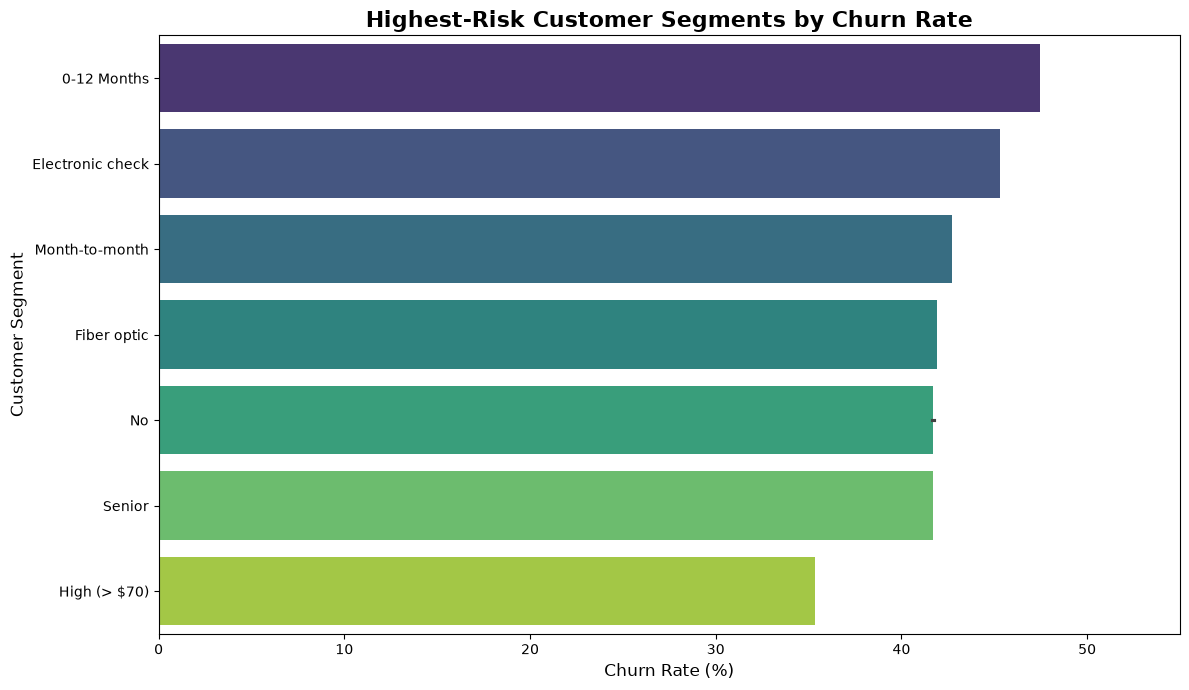

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.barplot(
    data=churn_comparison,
    x='Churn Rate',
    y='Segment',
    hue='Segment',
    palette='viridis',
    legend=False
)

plt.title(
    'Highest-Risk Customer Segments by Churn Rate',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Churn Rate (%)', fontsize=12)
plt.ylabel('Customer Segment', fontsize=12)

plt.xlim(0, 55)

plt.tight_layout()
plt.show()

In [82]:
# Compare numerical characteristics by churn status

numerical_comparison = df.groupby('Churn').agg(
    Customer_Count=('customerID', 'count'),
    Average_Tenure=('tenure', 'mean'),
    Median_Tenure=('tenure', 'median'),
    Average_Monthly_Charges=('MonthlyCharges', 'mean'),
    Average_Total_Charges=('TotalCharges_Clean', 'mean')
)

print("Numerical Comparison: Churned vs Retained Customers")

print(numerical_comparison.round(2))

Numerical Comparison: Churned vs Retained Customers
       Customer_Count  Average_Tenure  Median_Tenure  Average_Monthly_Charges  \
Churn                                                                           
No               5174           37.57           38.0                    61.27   
Yes              1869           17.98           10.0                    74.44   

       Average_Total_Charges  
Churn                         
No                   2549.91  
Yes                  1531.80  



### Numerical Analysis — Churned vs Retained Customers

| Metric | Retained Customers | Churned Customers |
|---|---:|---:|
| Customer Count | 5,174 | 1,869 |
| Average Tenure | 37.57 months | 17.98 months |
| Median Tenure | 38 months | 10 months |
| Average Monthly Charges | $61.27 | $74.44 |
| Average Total Charges | $2,549.91 | $1,531.80 |

**Key Findings:**
- Churned customers have considerably shorter tenure.
- The median tenure of churned customers is 10 months.
- Churned customers have higher average monthly charges.
- Retained customers have higher average total charges, consistent with their longer customer relationships.

**Business Insight:**

The first year of the customer relationship appears to be a critical retention period. The business should investigate early customer experiences, pricing concerns, and opportunities to encourage longer-term engagement.

**Note:** These findings describe associations and differences between groups; they do not establish causation.


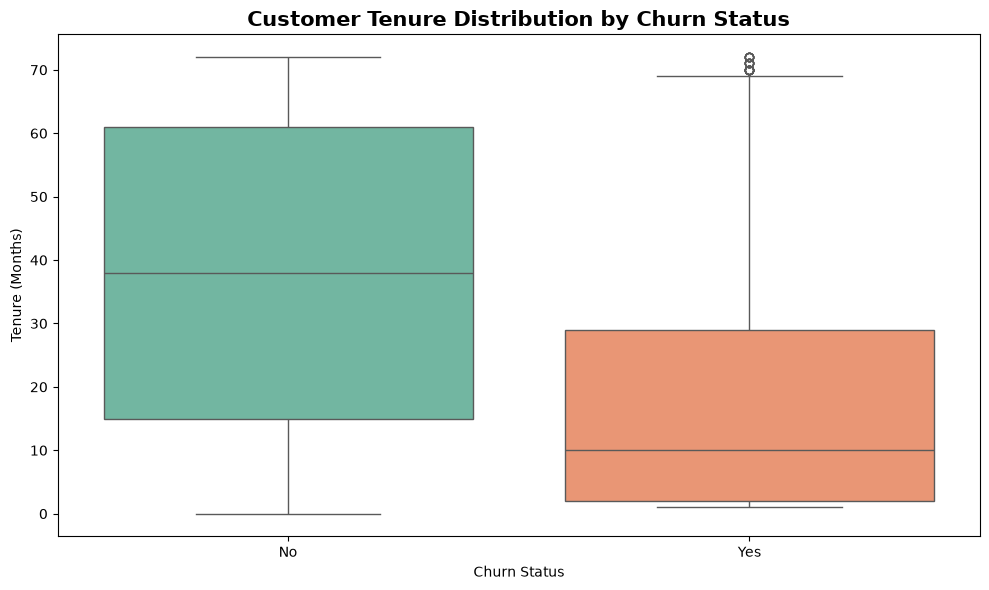

In [83]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Churn',
    y='tenure',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Customer Tenure Distribution by Churn Status',
          fontsize=15, fontweight='bold')

plt.xlabel('Churn Status')
plt.ylabel('Tenure (Months)')

plt.tight_layout()
plt.show()


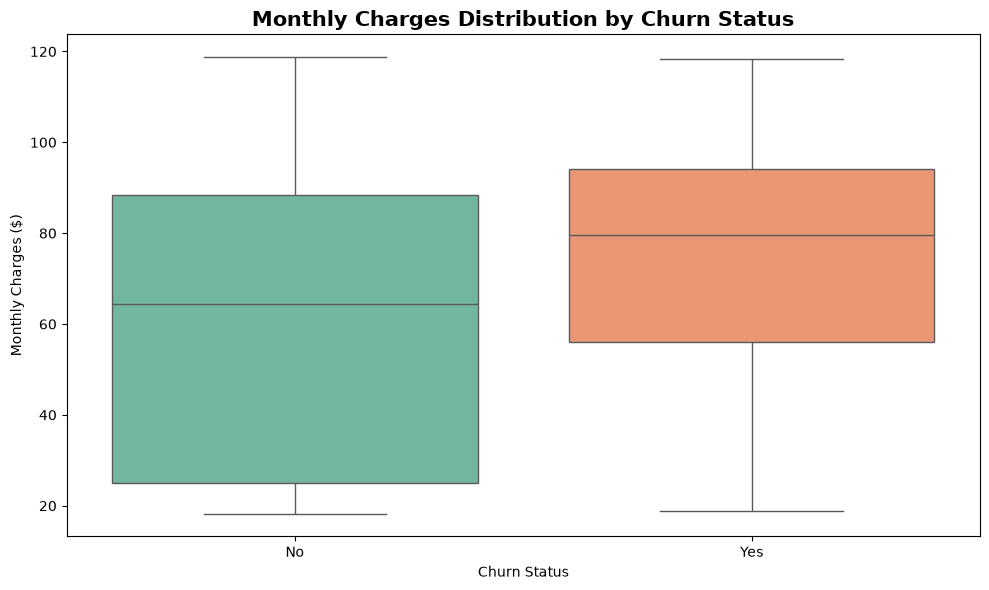

In [84]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Monthly Charges Distribution by Churn Status',
          fontsize=15, fontweight='bold')

plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges ($)')

plt.tight_layout()
plt.show()


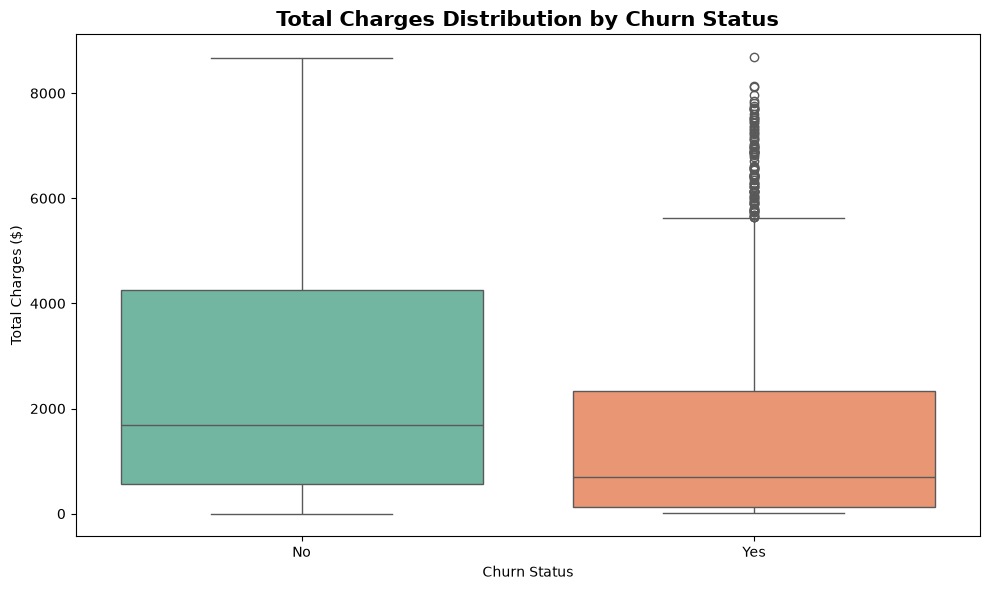

In [85]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Churn',
    y='TotalCharges_Clean',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Total Charges Distribution by Churn Status',
          fontsize=15, fontweight='bold')

plt.xlabel('Churn Status')
plt.ylabel('Total Charges ($)')

plt.tight_layout()
plt.show()



### Numerical Distribution Analysis — Boxplots

Three boxplots were created to compare numerical customer characteristics between churned and retained customers.

**1. Customer Tenure**
- Churned customers generally have shorter customer relationships.
- Their median tenure is considerably lower than retained customers.
- Early customer retention is an important business priority.

**2. Monthly Charges**
- Churned customers have higher average monthly charges.
- Pricing and service affordability may be worth investigating.

**3. Total Charges**
- Retained customers generally accumulate higher total charges.
- Longer customer relationships contribute to greater accumulated customer spending.

**Business Insight:**

The analysis highlights two important retention considerations: customer tenure and monthly pricing. The business should focus on improving early customer experiences and investigating pricing concerns.

**Note:** Boxplots show distributions and variation, not causal relationships.


In [86]:

# Select numerical columns for correlation analysis

correlation_data = df[
    ['tenure', 'MonthlyCharges', 'TotalCharges_Clean', 'SeniorCitizen']
]

# Calculate correlation matrix

correlation_matrix = correlation_data.corr()

print("Numerical Correlation Matrix:")
print(correlation_matrix.round(2))


Numerical Correlation Matrix:
                    tenure  MonthlyCharges  TotalCharges_Clean  SeniorCitizen
tenure                1.00            0.25                0.83           0.02
MonthlyCharges        0.25            1.00                0.65           0.22
TotalCharges_Clean    0.83            0.65                1.00           0.10
SeniorCitizen         0.02            0.22                0.10           1.00


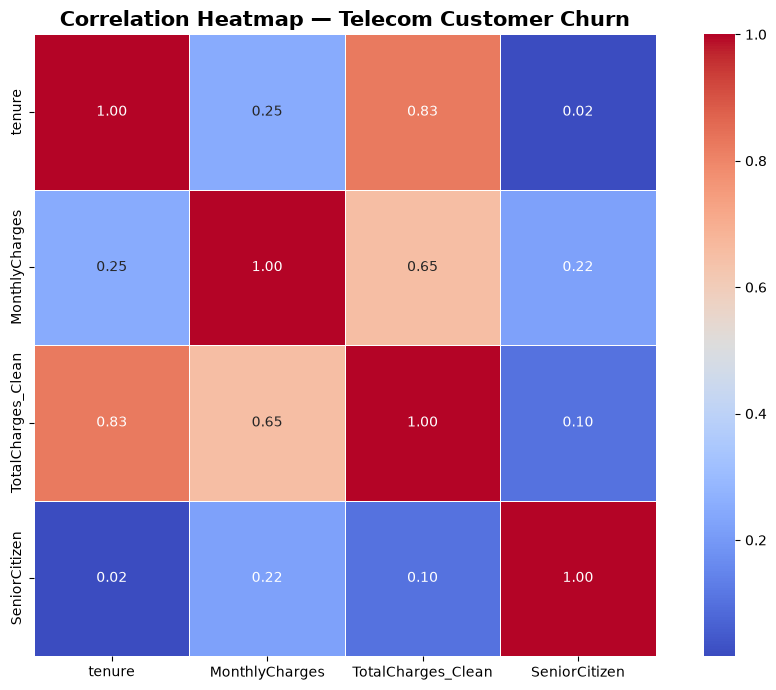

In [87]:

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title('Correlation Heatmap — Telecom Customer Churn',
          fontsize=15, fontweight='bold')

plt.tight_layout()
plt.show()



### Correlation Analysis — Numerical Variables

A Pearson correlation matrix and heatmap were created to examine relationships between numerical customer characteristics.

**Key Findings:**

- Tenure and Total Charges have a strong positive correlation (0.83).
- Monthly Charges and Total Charges have a moderate-to-strong positive correlation (0.65).
- Tenure and Monthly Charges have a weak positive correlation (0.25).
- Senior Citizen has weak correlations with the other numerical variables.

**Business Insights:**

- Longer customer relationships are associated with higher accumulated charges.
- Customers with higher monthly charges tend to accumulate more total charges.
- Customer tenure and monthly charges provide different perspectives for understanding customer behavior.

**Limitations:**
- Correlation does not establish causation.
- SeniorCitizen is a binary categorical variable encoded as 0 and 1.
- TotalCharges_Clean contains 11 placeholder zeros for originally missing values, which may slightly affect the correlation results.

**Conclusion:** Tenure and monthly charges are useful numerical characteristics for further customer churn investigation.


In [88]:

# Analyze churn by customer tenure and contract type

tenure_contract_analysis = df.groupby(
    ['TenureGroup', 'Contract'],
    observed=True
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=(
        'Churn',
        lambda x: (x == 'Yes').sum()
    )
).reset_index()

# Calculate churn rate

tenure_contract_analysis['Churn_Rate'] = (
    tenure_contract_analysis['Churned_Customers']
    / tenure_contract_analysis['Total_Customers']
    * 100
).round(2)

# Sort highest-risk combinations first

tenure_contract_analysis = tenure_contract_analysis.sort_values(
    'Churn_Rate',
    ascending=False
).reset_index(drop=True)

print("Churn Analysis: Customer Tenure + Contract Type")

print(tenure_contract_analysis)


Churn Analysis: Customer Tenure + Contract Type
     TenureGroup        Contract  Total_Customers  Churned_Customers  \
0    0-12 Months  Month-to-month             1994               1024   
1   13-24 Months  Month-to-month              737                278   
2   25-48 Months  Month-to-month              802                264   
3   49-72 Months  Month-to-month              342                 89   
4   49-72 Months        One year              634                 82   
5   25-48 Months        One year              518                 55   
6    0-12 Months        One year              124                 13   
7   13-24 Months        One year              197                 16   
8   49-72 Months        Two year             1263                 42   
9   25-48 Months        Two year              274                  6   
10   0-12 Months        Two year               68                  0   
11  13-24 Months        Two year               90                  0   

    Churn_Rate 

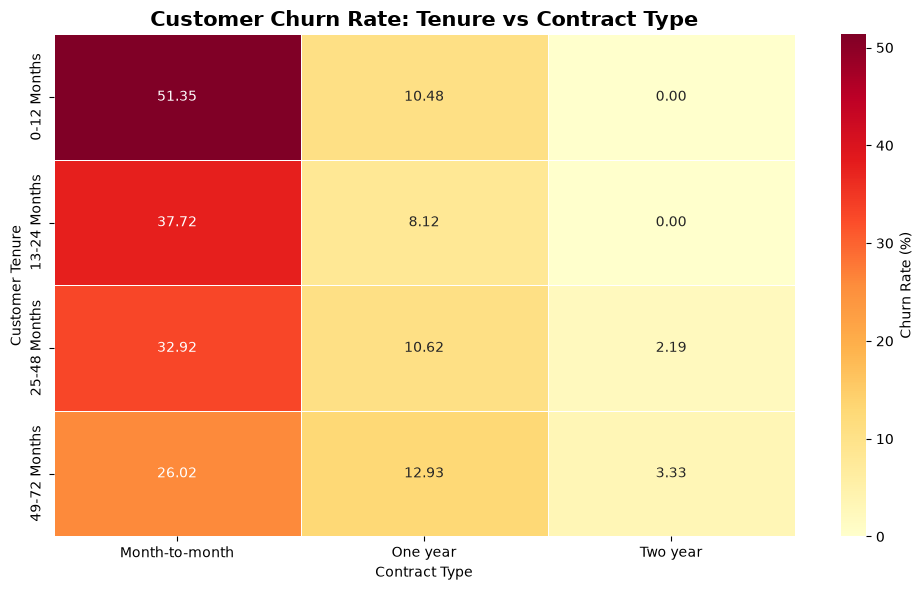

In [89]:

# Prepare data for the heatmap

tenure_contract_pivot = tenure_contract_analysis.pivot(
    index='TenureGroup',
    columns='Contract',
    values='Churn_Rate'
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    tenure_contract_pivot,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title(
    'Customer Churn Rate: Tenure vs Contract Type',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Contract Type')
plt.ylabel('Customer Tenure')

plt.tight_layout()
plt.show()



### Combined Risk Analysis — Customer Tenure + Contract Type

Customer churn was analyzed by combining tenure groups with contract types.

**Key Findings:**

- The highest-risk combination is 0–12 months tenure with a month-to-month contract, showing 51.35% churn.
- This segment contains 1,994 customers, of whom 1,024 churned.
- Month-to-month churn decreases as customer tenure increases.
- Two-year contract customers have consistently low churn rates across tenure groups.
- The 0% churn observed in two small two-year contract groups should be interpreted cautiously.

**Business Recommendations:**

1. Introduce early retention programs for new month-to-month customers.
2. Improve onboarding and customer support during the first 12 months.
3. Encourage suitable customers to consider longer-term contracts.
4. Monitor new customer churn regularly.

**Conclusion:** Early tenure combined with a month-to-month contract represents a major customer retention risk.

**Note:** These findings show associations between customer characteristics and churn, not proof of causation.


In [90]:

# Analyze churn by monthly charges group and contract type

charges_contract_analysis = df.groupby(
    ['MonthlyChargesGroup', 'Contract'],
    observed=True
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=(
        'Churn',
        lambda x: (x == 'Yes').sum()
    )
).reset_index()

# Calculate churn rate

charges_contract_analysis['Churn_Rate'] = (
    charges_contract_analysis['Churned_Customers']
    / charges_contract_analysis['Total_Customers']
    * 100
).round(2)

# Sort by churn rate

charges_contract_analysis = charges_contract_analysis.sort_values(
    'Churn_Rate',
    ascending=False
).reset_index(drop=True)

print("Churn Analysis: Monthly Charges + Contract Type")

print(charges_contract_analysis)


Churn Analysis: Monthly Charges + Contract Type
  MonthlyChargesGroup        Contract  Total_Customers  Churned_Customers  \
0        High (> $70)  Month-to-month             2097               1105   
1    Medium ($35-$70)  Month-to-month             1070                378   
2        Low (<= $35)  Month-to-month              708                172   
3        High (> $70)        One year              717                125   
4    Medium ($35-$70)        One year              371                 29   
5        High (> $70)        Two year              769                 37   
6        Low (<= $35)        One year              385                 12   
7    Medium ($35-$70)        Two year              284                  6   
8        Low (<= $35)        Two year              642                  5   

   Churn_Rate  
0       52.69  
1       35.33  
2       24.29  
3       17.43  
4        7.82  
5        4.81  
6        3.12  
7        2.11  
8        0.78  



charges_contract_pivot = charges_contract_analysis.pivot(
    index='MonthlyChargesGroup',
    columns='Contract',
    values='Churn_Rate'
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    charges_contract_pivot,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title(
    'Customer Churn Rate: Monthly Charges vs Contract Type',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Contract Type')
plt.ylabel('Monthly Charges Group')

plt.tight_layout()
plt.show()



### Combined Risk Analysis — Monthly Charges + Contract Type

Customer churn was analyzed by combining monthly charge groups with contract types.

**Key Findings:**

- The highest-risk combination is High Monthly Charges (over $70) with a Month-to-month contract, showing 52.69% churn.
- This segment contains 2,097 customers, of whom 1,105 churned.
- Within each contract type, higher monthly charges are associated with higher churn.
- Two-year contract customers show substantially lower churn across all monthly charge groups.
- The lowest observed churn rate is 0.78% among customers with low monthly charges and two-year contracts.

**Business Recommendations:**

1. Investigate pricing concerns among high-charge month-to-month customers.
2. Offer suitable service plans that better match customer needs and budgets.
3. Strengthen retention efforts for customers with high monthly charges.
4. Evaluate longer-term contract incentives without pressuring customers.

**Conclusion:** High monthly charges combined with flexible month-to-month contracts represent a major customer retention risk.

**Note:** These results show associations and do not establish causation.


In [91]:

# Analyze churn by internet service and contract type

internet_contract_analysis = df.groupby(
    ['InternetService', 'Contract'],
    observed=True
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=(
        'Churn',
        lambda x: (x == 'Yes').sum()
    )
).reset_index()

# Calculate churn rate

internet_contract_analysis['Churn_Rate'] = (
    internet_contract_analysis['Churned_Customers']
    / internet_contract_analysis['Total_Customers']
    * 100
).round(2)

# Sort highest-risk combinations first

internet_contract_analysis = internet_contract_analysis.sort_values(
    'Churn_Rate',
    ascending=False
).reset_index(drop=True)

print("Churn Analysis: Internet Service + Contract Type")

print(internet_contract_analysis)


Churn Analysis: Internet Service + Contract Type
  InternetService        Contract  Total_Customers  Churned_Customers  \
0     Fiber optic  Month-to-month             2128               1162   
1             DSL  Month-to-month             1223                394   
2     Fiber optic        One year              539                104   
3              No  Month-to-month              524                 99   
4             DSL        One year              570                 53   
5     Fiber optic        Two year              429                 31   
6              No        One year              364                  9   
7             DSL        Two year              628                 12   
8              No        Two year              638                  5   

   Churn_Rate  
0       54.61  
1       32.22  
2       19.29  
3       18.89  
4        9.30  
5        7.23  
6        2.47  
7        1.91  
8        0.78  


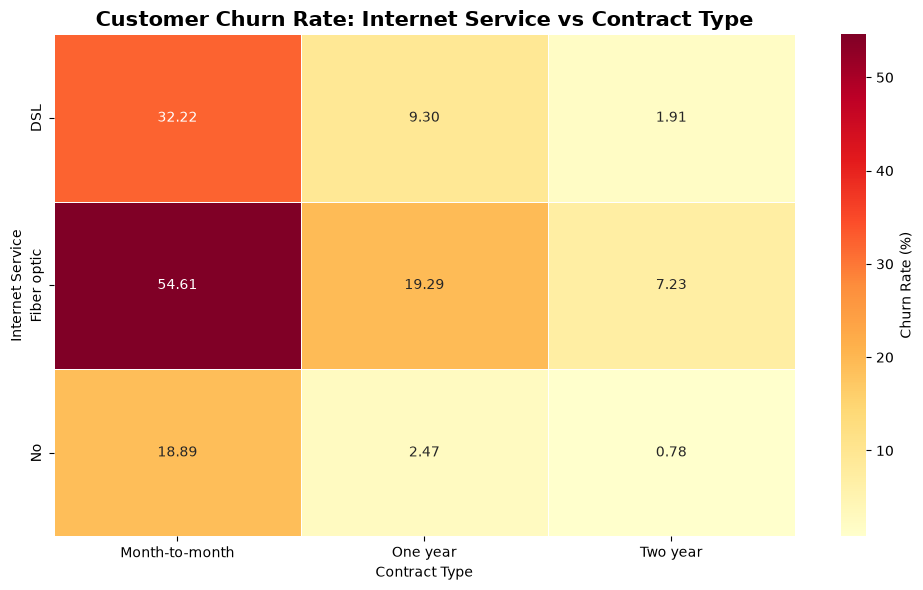

In [92]:

internet_contract_pivot = internet_contract_analysis.pivot(
    index='InternetService',
    columns='Contract',
    values='Churn_Rate'
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    internet_contract_pivot,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title(
    'Customer Churn Rate: Internet Service vs Contract Type',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Contract Type')
plt.ylabel('Internet Service')

plt.tight_layout()
plt.show()



### Combined Risk Analysis — Internet Service + Contract Type

Customer churn was analyzed by combining internet service categories with contract types.

**Key Findings:**

- Fiber Optic customers with Month-to-month contracts have the highest churn rate (54.61%).
- This segment contains 2,128 customers, of whom 1,162 churned.
- Fiber Optic customers with Two-year contracts have a much lower churn rate (7.23%).
- Month-to-month contracts show higher churn across all internet service categories.
- Customers without internet service and on Two-year contracts have the lowest observed churn rate (0.78%).

**Business Recommendations:**

1. Investigate pricing, service quality, and satisfaction among Fiber Optic customers.
2. Prioritize retention efforts for Fiber Optic month-to-month subscribers.
3. Monitor customer experience during the early stages of service.
4. Explore appropriate long-term contract incentives.

**Conclusion:** Fiber Optic service combined with a Month-to-month contract represents a major customer retention risk.

**Note:** These findings indicate associations and do not establish causation.


In [93]:

# Analyze churn by payment method and contract type

payment_contract_analysis = df.groupby(
    ['PaymentMethod', 'Contract'],
    observed=True
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=(
        'Churn',
        lambda x: (x == 'Yes').sum()
    )
).reset_index()

# Calculate churn rate

payment_contract_analysis['Churn_Rate'] = (
    payment_contract_analysis['Churned_Customers']
    / payment_contract_analysis['Total_Customers']
    * 100
).round(2)

# Sort highest-risk combinations first

payment_contract_analysis = payment_contract_analysis.sort_values(
    'Churn_Rate',
    ascending=False
).reset_index(drop=True)

print("Churn Analysis: Payment Method + Contract Type")

print(payment_contract_analysis)


Churn Analysis: Payment Method + Contract Type
                PaymentMethod        Contract  Total_Customers  \
0            Electronic check  Month-to-month             1850   
1   Bank transfer (automatic)  Month-to-month              589   
2     Credit card (automatic)  Month-to-month              543   
3                Mailed check  Month-to-month              893   
4            Electronic check        One year              347   
5     Credit card (automatic)        One year              398   
6   Bank transfer (automatic)        One year              391   
7            Electronic check        Two year              168   
8                Mailed check        One year              337   
9   Bank transfer (automatic)        Two year              564   
10    Credit card (automatic)        Two year              581   
11               Mailed check        Two year              382   

    Churned_Customers  Churn_Rate  
0                 994       53.73  
1                 201 

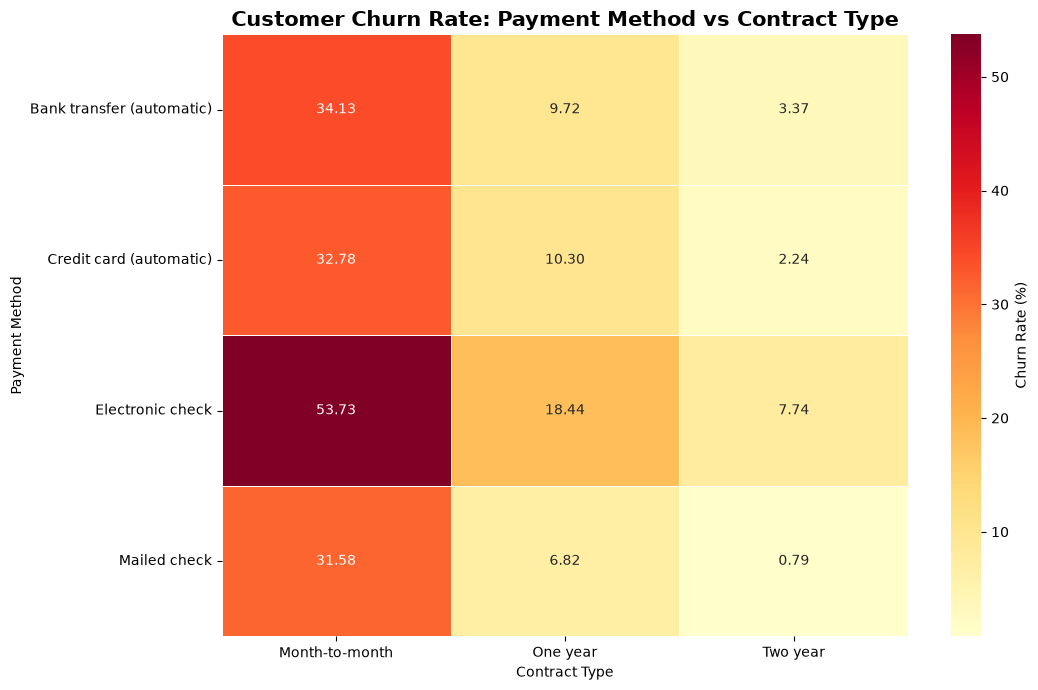

In [94]:

payment_contract_pivot = payment_contract_analysis.pivot(
    index='PaymentMethod',
    columns='Contract',
    values='Churn_Rate'
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    payment_contract_pivot,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title(
    'Customer Churn Rate: Payment Method vs Contract Type',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Contract Type')
plt.ylabel('Payment Method')

plt.tight_layout()
plt.show()



### Combined Risk Analysis — Payment Method + Contract Type

Customer churn was analyzed by combining payment methods with contract types.

**Key Findings:**

- Electronic Check users with Month-to-month contracts have the highest churn rate (53.73%).
- This segment contains 1,850 customers, of whom 994 churned.
- Electronic Check users show higher churn than other payment groups within each contract type.
- Two-year contract customers have consistently lower churn across all payment methods.
- The lowest observed churn rate is 0.79% among Mailed Check users with Two-year contracts.

**Business Recommendations:**

1. Investigate potential payment friction among Electronic Check users.
2. Promote convenient automatic payment methods where appropriate.
3. Prioritize retention campaigns for Electronic Check users with Month-to-month contracts.
4. Monitor payment experience and customer satisfaction.

**Conclusion:** Electronic Check combined with a Month-to-month contract represents a major customer retention risk.

**Note:** These findings show associations and do not establish causation.



# Python EDA — Executive Summary
## Telecom Customer Churn & Retention Analytics

### 1. Project Overview
Exploratory Data Analysis was performed on the IBM Telco Customer Churn dataset to identify customer behavior patterns, understand churn characteristics, and discover high-risk customer segments.

### 2. Dataset Overview
- Total Customers: 7,043
- Total Features: 21 original columns
- Churned Customers: 1,869
- Retained Customers: 5,174
- Overall Churn Rate: 26.54%

### 3. Major Findings

**Customer Behavior**
- Customers with 0–12 months tenure have a 47.44% churn rate.
- Month-to-month customers have a 42.71% churn rate.
- Electronic Check users have a 45.29% churn rate.
- Fiber Optic customers have a 41.89% churn rate.

**Numerical Analysis**
- Average tenure of churned customers: 17.98 months.
- Average tenure of retained customers: 37.57 months.
- Average monthly charges of churned customers: $74.44.
- Average monthly charges of retained customers: $61.27.

**Correlation Analysis**
- Tenure and Total Charges: 0.83 correlation.
- Monthly Charges and Total Charges: 0.65 correlation.

### 4. Highest-Risk Customer Combinations

| Customer Segment | Churn Rate |
|---|---:|
| Fiber Optic + Month-to-month | 54.61% |
| Electronic Check + Month-to-month | 53.73% |
| High Charges + Month-to-month | 52.69% |
| New Customers + Month-to-month | 51.35% |

### 5. Business Recommendations

1. Prioritize retention programs for customers during their first 12 months.
2. Investigate pricing and service concerns among high-charge customers.
3. Improve customer experience for Fiber Optic subscribers.
4. Investigate payment friction among Electronic Check users.
5. Encourage suitable customers to consider longer-term contracts.
6. Monitor high-risk customer segments regularly.

### 6. Data Limitations
- Eleven original TotalCharges values were blank and replaced with zero in the cleaned analytical column.
- Correlation and segment analysis identify associations, not causation.
- Historical churn patterns do not guarantee future customer behavior.

### 7. Conclusion
The analysis identifies early-tenure customers, month-to-month subscribers, Fiber Optic users, and Electronic Check users as important retention priorities.

Combining multiple customer characteristics reveals higher-risk segments than examining individual characteristics alone.

These findings can support customer retention strategies and provide a foundation for the Power BI dashboard.
